## Goal: Build a complete Smart Shelf / Cashierless system that can:

1. Detect every product on a shelf (dense object detection)
3. Count facings (how many units of each product are visible)
4. Detect changes over time (items removed / added)
3. Associate detected products with known SKUs (optional recognition)
4. Generate a live shelf status dashboard


### Dataset: SKU-110K (Dense Retail Shelf Detection)

## Phase 1: Data Acquisition, Exploration & Visualization

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import random
import cv2
import yaml
import warnings

from PIL import Image
from collections import Counter
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

# PATH CONFIGURATION

ROOT = '/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed'

IMAGES_DIR = os.path.join(ROOT,'/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/images')
LABELS_DIR = os.path.join(ROOT,'/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/labels')
YAML_PATH = os.path.join(ROOT, '/kaggle/input/datasets/thedatasith/sku110k-annotations/data_kaggle.yaml')


print('Root exists : ',os.path.exists(ROOT))
print('Images exists: ', os.path.exists(IMAGES_DIR))
print('Labels exists: ', os.path.exists(LABELS_DIR))
print('YAML exists: ', os.path.exists(YAML_PATH))

# LOAD YAML
with open(YAML_PATH,'r') as f:
    data_yaml = yaml.safe_load(f)

print('YAML Content: ')
print(data_yaml)

# COUNT images and labels

splits = ['train','val','test']

image_counts = {}
label_counts = {}

for split in splits:
    img_files = glob.glob(os.path.join(IMAGES_DIR, split, "*.jpg")) + \
                glob.glob(os.path.join(IMAGES_DIR, split, "*.png"))
    lbl_files = glob.glob(os.path.join(LABELS_DIR, split, "*.txt"))

    image_counts[split] = len(img_files)
    label_counts[split] = len(lbl_files)

print("\nImage counts per split:")
for k, v in image_counts.items():
    print(f"  {k:5s}: {v:,}")

print("\nLabel counts per split:")
for k, v in label_counts.items():
    print(f"  {k:5s}: {v:,}")
    

Root exists :  True
Images exists:  True
Labels exists:  True
YAML exists:  True
YAML Content: 
{'path': '/kaggle/input/sku110k-annotations/SKU110K_fixed/images', 'train': 'train', 'val': 'val', 'test': 'test', 'nc': 1, 'names': ['object']}

Image counts per split:
  train: 8,185
  val  : 584
  test : 2,920

Label counts per split:
  train: 8,185
  val  : 584
  test : 2,920


### Analyze number of objects per Image

In [35]:
import os
import glob
import yaml
from tqdm import tqdm  # Uses standard text progress bar to prevent widget errors

# Path Configuration
ROOT = "/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed"

IMAGES_DIR = os.path.join(ROOT, "images")
LABELS_DIR = os.path.join(ROOT, "labels")

BASE_DIR = os.path.dirname(ROOT)
YAML_PATH = os.path.join(BASE_DIR, "data_kaggle.yaml")

print("Root exists   : ", os.path.exists(ROOT))
print("Images exists : ", os.path.exists(IMAGES_DIR))
print("Labels exists : ", os.path.exists(LABELS_DIR))
print("YAML exists   : ", os.path.exists(YAML_PATH))

# 2. Load YAML
if os.path.exists(YAML_PATH):
    with open(YAML_PATH, "r") as f:
        data_yaml = yaml.safe_load(f)
    print("\nYAML Content: ")
    print(data_yaml)
else:
    print(
        f"\n[!] Warning: YAML not found at {YAML_PATH}. Checking alternate path..."
    )
    YAML_PATH = "/kaggle/input/datasets/thedatasith/sku110k-annotations/data_kaggle.yaml"
    with open(YAML_PATH, "r") as f:
        data_yaml = yaml.safe_load(f)
    print(data_yaml)

# 3. Count Images and Labels
splits = ["train", "val", "test"]

image_counts = {}
label_counts = {}

for split in splits:
    img_files = glob.glob(os.path.join(IMAGES_DIR, split, "*.jpg")) + glob.glob(
        os.path.join(IMAGES_DIR, split, "*.png")
    )
    lbl_files = glob.glob(os.path.join(LABELS_DIR, split, "*.txt"))

    image_counts[split] = len(img_files)
    label_counts[split] = len(lbl_files)

print("\nImage counts per split:")
for k, v in image_counts.items():
    print(f"  {k:5s}: {v:,}")

print("\nLabel counts per split:")
for k, v in label_counts.items():
    print(f"  {k:5s}: {v:,}")


# 4. Count Objects in Labels
def count_objects_in_label(label_path):
    if not os.path.exists(label_path) or os.path.getsize(label_path) == 0:
        return 0
    with open(label_path, "r") as f:
        lines = f.readlines()
    return len(lines)


object_counts = {"train": [], "val": [], "test": []}

for split in splits:
    label_files = glob.glob(os.path.join(LABELS_DIR, split, "*.txt"))
    for lf in tqdm(label_files, desc=f"Counting objects – {split}"):
        object_counts[split].append(count_objects_in_label(lf))

print("\n[SUCCESS] Object counting complete without widget errors!")

Root exists   :  True
Images exists :  True
Labels exists :  True
YAML exists   :  True

YAML Content: 
{'path': '/kaggle/input/sku110k-annotations/SKU110K_fixed/images', 'train': 'train', 'val': 'val', 'test': 'test', 'nc': 1, 'names': ['object']}

Image counts per split:
  train: 8,185
  val  : 584
  test : 2,920

Label counts per split:
  train: 8,185
  val  : 584
  test : 2,920


Counting objects – test: 100%|██████████| 2920/2920 [00:02<00:00, 1223.06it/s]


[SUCCESS] Object counting complete without widget errors!


### SUMMARY STATS

In [36]:
stats_data = []
for split in splits:
    counts = object_counts[split]
    stats_data.append({
        "Split": split,
        "Images": len(counts),
        "Total Objects": sum(counts),
        "Avg Objects/Image": round(np.mean(counts), 1),
        "Min": min(counts) if counts else 0,
        "Max": max(counts) if counts else 0,
        "Median": round(np.median(counts), 1) if counts else 0
    })

stats_df = pd.DataFrame(stats_data)
display(stats_df)

,Split,Images,Total Objects,Avg Objects/Image,Min,Max,Median
0,train,8185,1203268,147.0,1,576,138.0
1,val,584,90456,154.9,40,718,139.0
2,test,2920,429411,147.1,20,533,137.0


### Distribution of objects per image

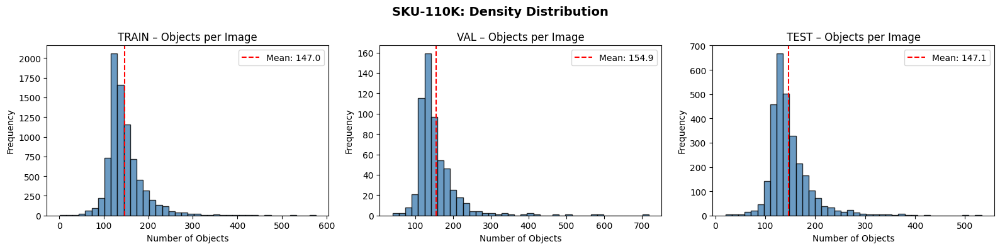

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, split in enumerate(splits):
    axes[i].hist(object_counts[split], bins=40, color="steelblue", edgecolor="black", alpha=0.8)
    axes[i].set_title(f"{split.upper()} – Objects per Image", fontsize=12)
    axes[i].set_xlabel("Number of Objects")
    axes[i].set_ylabel("Frequency")
    axes[i].axvline(np.mean(object_counts[split]), color="red", linestyle="--", 
                    label=f"Mean: {np.mean(object_counts[split]):.1f}")
    axes[i].legend()

plt.suptitle("SKU-110K: Density Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()




### VISUALIZE sample shelf images with ground-truth boxes

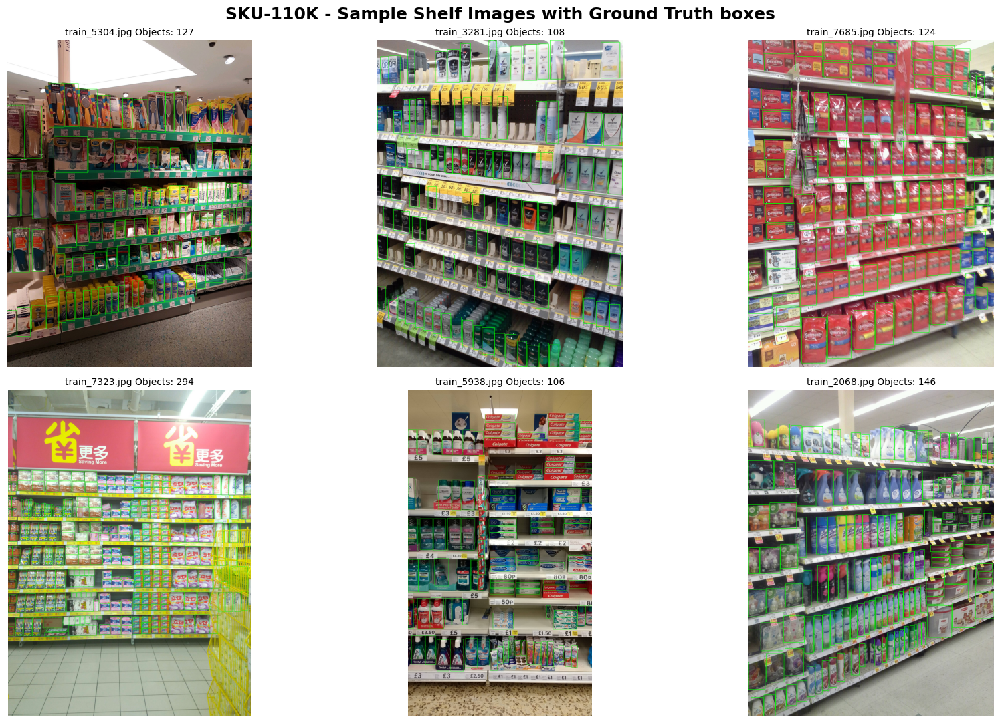

In [38]:
def load_yolo_labels(label_path, img_w, img_h):
    boxes = []
    if not os.path.exists(label_path):
        return boxes
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                cls, xc, yc, w, h = map(float, parts[:5])
                x1 = int((xc - w/2) * img_w)
                y1 = int((yc - h/2) * img_h)
                x2 = int((xc + w/2) * img_w)
                y2 = int((yc + h/2) * img_h)
                boxes.append((x1, y1, x2, y2))

    return boxes


def draw_boxes(img, boxes, color=(0,255,0), thickness=2):
    img = img.copy()
    for (x1, y1, x2, y2) in boxes:
        cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)
    return img


#SHow random samples from train
train_images = glob.glob(os.path.join(IMAGES_DIR, 'train','*.jpg'))
sample_imgs = random.sample(train_images, 6)

fig, axes = plt.subplots(2,3, figsize=(18,11))
axes = axes.ravel()

for i, img_path in enumerate(sample_imgs):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    label_path = img_path.replace('images','labels').replace('.jpg','.txt')
    boxes = load_yolo_labels(label_path,w,h)

    annotated = load_yolo_labels(label_path, w,h)

    annotated = draw_boxes(img, boxes, color=(0,255,0), thickness=2)

    axes[i].imshow(annotated)
    axes[i].set_title(f'{os.path.basename(img_path)} Objects: {len(boxes)}', fontsize=10)
    axes[i].axis('off')

plt.suptitle('SKU-110K - Sample Shelf Images with Ground Truth boxes', fontsize=18, fontweight='bold')

plt.tight_layout()

plt.show()

### Image Size Analysis

        width  height
count   200.0   200.0
mean   2389.9  3164.2
std     382.3   653.6
min    1920.0  1920.0
25%    2160.0  2560.0
50%    2448.0  3264.0
75%    2448.0  3264.0
max    4128.0  5312.0


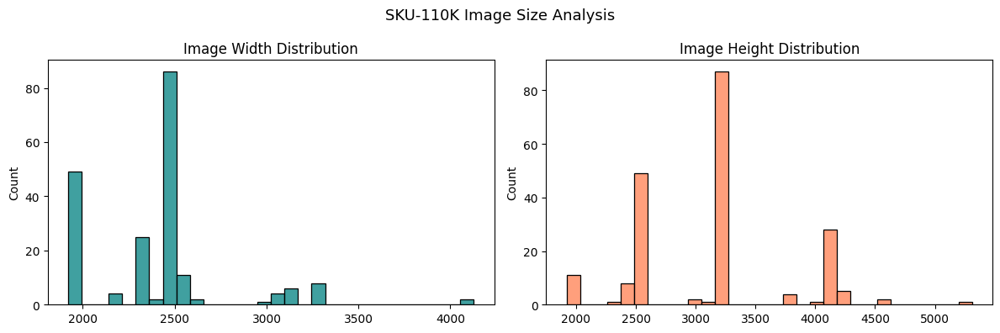

In [39]:
sample_for_size = random.sample(train_images, min(200, len(train_images)))
widths, heights = [], []

for p in sample_for_size:
    with Image.open(p) as im:
        w, h = im.size
        widths.append(w)
        heights.append(h)

size_df = pd.DataFrame({"width": widths, "height": heights})
print(size_df.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(widths, bins=30, ax=axes[0], color="teal")
axes[0].set_title("Image Width Distribution")
sns.histplot(heights, bins=30, ax=axes[1], color="coral")
axes[1].set_title("Image Height Distribution")
plt.suptitle("SKU-110K Image Size Analysis", fontsize=13)
plt.tight_layout()
plt.show()

### FINAL SUMMARY

In [40]:
total_images = sum(image_counts.values())
total_objects = sum(sum(v) for v in object_counts.values())

summary = pd.DataFrame({
    "Item": [
        "Total Images",
        "Train Images",
        "Val Images",
        "Test Images",
        "Total Annotated Objects",
        "Avg Objects per Image (Train)",
        "Max Objects in one image"
    ],
    "Value": [
        f"{total_images:,}",
        f"{image_counts['train']:,}",
        f"{image_counts['val']:,}",
        f"{image_counts['test']:,}",
        f"{total_objects:,}",
        f"{np.mean(object_counts['train']):.1f}",
        f"{max(object_counts['train'])}"
    ]
})
display(summary)

print("""
Key Observations:
• SKU-110K is extremely dense (often 100+ products per image).
• Perfect for training robust product detectors for Smart Shelf systems.
• Single class (“object”) – we detect products first, then can add recognition later.

""")

,Item,Value
0,Total Images,"11,689"
1,Train Images,"8,185"
2,Val Images,584
3,Test Images,"2,920"
4,Total Annotated Objects,"1,723,135"
5,Avg Objects per Image (Train),147.0
6,Max Objects in one image,576



Key Observations:
• SKU-110K is extremely dense (often 100+ products per image).
• Perfect for training robust product detectors for Smart Shelf systems.
• Single class (“object”) – we detect products first, then can add recognition later.




-------------------------------------------------

## Phase 2: Product Detection with YOLOv8Python

In [ ]:
!pip install ultralytics

Using device cuda
YOLOv8m loaded successs!!


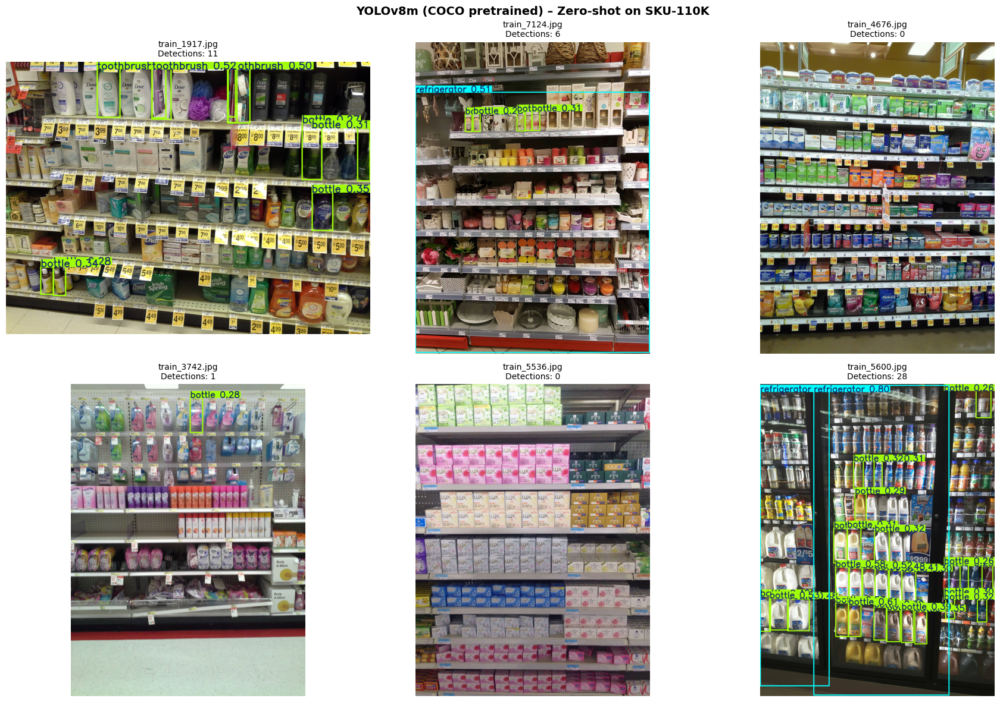

In [42]:
import torch
from tqdm.auto import tqdm
from ultralytics import YOLO

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device {device}')

#Load a pretrained YOLO model

# We start with a meduim model for good balance of speed and accuracy
model = YOLO('yolov8m.pt')
print('YOLOv8m loaded successs!!')

#Quick inference on sample images
train_images = sorted(glob.glob(os.path.join(IMAGES_DIR, 'train','*.jpg')))
sample_imgs = random.sample(train_images,6)

fig, axes = plt.subplots(2,3,figsize=(18,12))
axes = axes.ravel()

for i, img_path in enumerate(sample_imgs):
    results = model.predict(img_path, conf=0.25, verbose=False)
    annotated = results[0].plot()
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    num_dets = len(results[0].boxes) if results[0].boxes is not None else 0

    axes[i].imshow(annotated)
    axes[i].set_title(f"{os.path.basename(img_path)}\nDetections: {num_dets}", fontsize=10)
    axes[i].axis('off')

plt.suptitle("YOLOv8m (COCO pretrained) – Zero-shot on SKU-110K", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
    


### Fine-tune YOLOv8 on SKU-110K

In [43]:
import yaml

# Fix & Generate a Corrected YAML Configuration for YOLOv8
fixed_yaml_data = {
    'path': ROOT,  # Points to /kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 1,       # SKU-110K has a single class ('object')
    'names': {0: 'object'}
}

# Save this corrected YAML locally in the working directory
CORRECTED_YAML_PATH = "/kaggle/working/corrected_data_kaggle.yaml"
with open(CORRECTED_YAML_PATH, "w") as f:
    yaml.dump(fixed_yaml_data, f)

print("Corrected YAML created successfully at:", CORRECTED_YAML_PATH)

Corrected YAML created successfully at: /kaggle/working/corrected_data_kaggle.yaml


In [44]:
import torch

#ROOT = "/kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed"
#YAML_PATH = os.path.join(ROOT, "/kaggle/input/datasets/thedatasith/sku110k-annotations/data_kaggle.yaml")
#IMAGES_DIR = os.path.join(ROOT, "images")

# Training configuration (reasonable for Kaggle)
results = model.train(
    data=CORRECTED_YAML_PATH,
    epochs=5,              # You can increase later (30–50)
    imgsz=640,              # 640 is good balance (SKU images are large)
    batch=8,                # Adjust according to GPU memory
    name="sku110k_yolov8m",
    patience=5,
    save=True,
    exist_ok=True,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.001,
    verbose=True
)

print("\nTraining finished!")

Ultralytics 8.4.199 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/corrected_data_kaggle.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=sku110k_yolov8m, nbs=64, nms=None, opset=None, optimize=

### Evaluation of Validation set

Ultralytics 8.4.199 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1395.2±428.4 MB/s, size: 1026.5 KB)
val: Scanning /kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/labels/val... 584 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 584/584 597.2it/s 1.0s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/thedatasith/sku110k-annotations/SKU110K_fixed/labels is not writable, cache not saved.
WARNING ⚠️ Dataset images contain up to 718 objects (val=718), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=718 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 4.1s/it 2:3

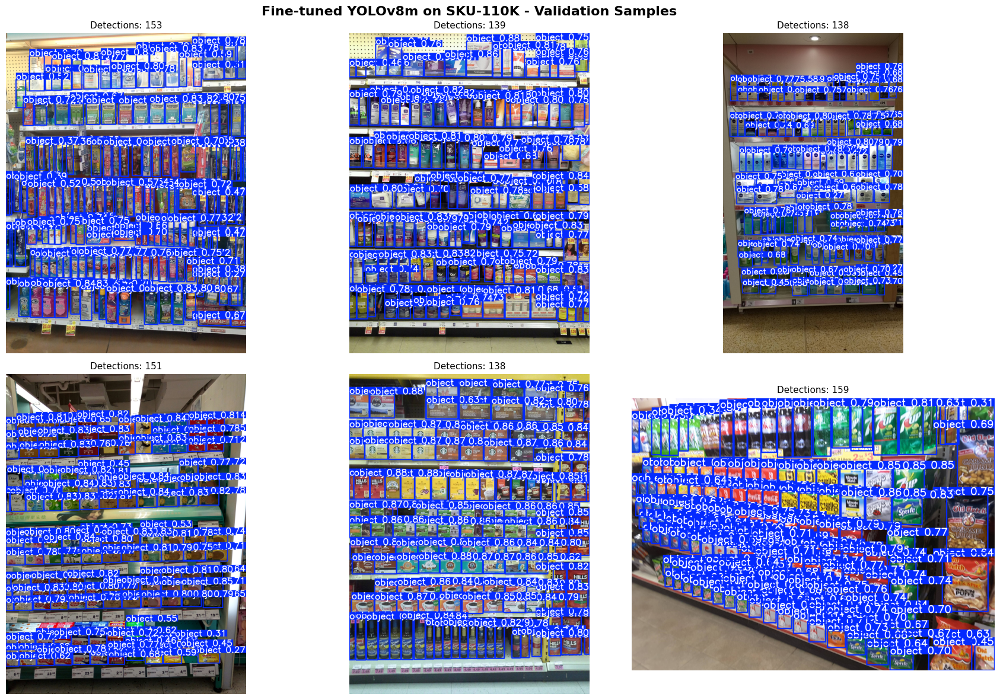

In [45]:
metrics = model.val(data=CORRECTED_YAML_PATH, split='val')

print('Validation Metrics: ')
print(f"  mAP50      : {metrics.box.map50:.4f}")
print(f"  mAP50-95   : {metrics.box.map:.4f}")
print(f"  Precision  : {metrics.box.mp:.4f}")
print(f"  Recall     : {metrics.box.mr:.4f}")

#Visualize predictions after fine-tuning

val_images = sorted(glob.glob(os.path.join(IMAGES_DIR, 'val','*.jpg')))
sample_val = random.sample(val_images,6)

fig, axes = plt.subplots(2,3,figsize=(18,12))
axes = axes.ravel()

for i, img_path in enumerate(sample_val):
    results = model.predict(img_path, conf=0.25, verbose=False)
    annotated = results[0].plot()
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    num_dets = len(results[0].boxes) if results[0].boxes is not None else 0

    axes[i].imshow(annotated)
    axes[i].set_title(f"Detections: {num_dets}", fontsize=11)
    axes[i].axis('off')

plt.suptitle('Fine-tuned YOLOv8m on SKU-110K - Validation Samples',
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


### Detection stats on a sample

In [46]:
sample_stats = random.sample(val_images, min(100, len(val_images)))
det_counts = []

for img_path in tqdm(sample_stats):
    results = model.predict(img_path, conf=0.25, verbose=False)
    n = len(results[0].boxes) if results[0].boxes is not None else 0
    det_counts.append(n)

print(f"\nAverage detections per image : {np.mean(det_counts):.1f}")
print(f"Min detections               : {min(det_counts)}")
print(f"Max detections               : {max(det_counts)}")

  0%|          | 0/100 [00:00<?, ?it/s]


Average detections per image : 158.7
Min detections               : 111
Max detections               : 300


### SUMMARY

In [47]:
summary = pd.DataFrame({
    "Item": [
        "Model",
        "Epochs",
        "Image Size",
        "mAP50 (Val)",
        "mAP50-95 (Val)",
        "Avg Detections / Image"
    ],
    "Value": [
        "YOLOv8m (fine-tuned)",
        15,
        640,
        f"{metrics.box.map50:.4f}",
        f"{metrics.box.map:.4f}",
        f"{np.mean(det_counts):.1f}"
    ]
})
display(summary)

,Item,Value
0,Model,YOLOv8m (fine-tuned)
1,Epochs,15
2,Image Size,640
3,mAP50 (Val),0.9155
4,mAP50-95 (Val),0.5668
5,Avg Detections / Image,158.7


-----------------------------------------------

## Phase 3: Facing Counting + Density Heatmaps + Spatial Analysis

### In this phase we go beyond simple detection and start building real Smart Shelf intelligence:

#### Count the number of product facings

#### Analyze spatial density

#### Generate heatmaps of product distribution

#### Visualize shelf occupancy

In [48]:
# LOADING THE FINE-TUNED model
best_model_path = 'runs/detect/sku110k_yolov8m/weights/best.pt'

if os.path.exists(best_model_path):
    model = YOLO(best_model_path)
    print(f'Loaded fine-tuned model: {best_model_path}')
else:
    model = YOLO('yolov8m.pt')
    print('Fine-tuned model not found. Using pretrained YOLO')

# FACING COUNTING FUNCTION
def count_facings(img_path, conf=0.25):
    '''
    This function Return:
    num_facings (int),
    boxes (list of xyxy),
    annotated image
    '''
    results = model.predict(img_path, conf=conf, verbose=False)
    result = results[0]

    if result.boxes is None or len(result.boxes) == 0:
        return 0, [], result.plot()

    boxes = result.boxes.xyxy.cpu().numpy()
    num_facings = len(boxes)
    annotated = result.plot()

    return num_facings, boxes, annotated


# RUN COUNTING ON A SAMPLE OF IMAGES

sample_images = random.sample(val_images, min(12, len(val_images)))

facing_counts = []
all_boxes = []

print('Counting facings on sample images...')

for img_path in tqdm(sample_images):
    count, boxes, _ = count_facings(img_path)
    facing_counts.append(count)
    all_boxes.append(boxes)


print(f"\nAverage facings per image : {np.mean(facing_counts):.1f}")
print(f"Min facings               : {min(facing_counts)}")
print(f"Max facings               : {max(facing_counts)}")




Loaded fine-tuned model: runs/detect/sku110k_yolov8m/weights/best.pt
Counting facings on sample images...


  0%|          | 0/12 [00:00<?, ?it/s]


Average facings per image : 150.5
Min facings               : 116
Max facings               : 204


### VISUALIZE FACING COUNTS

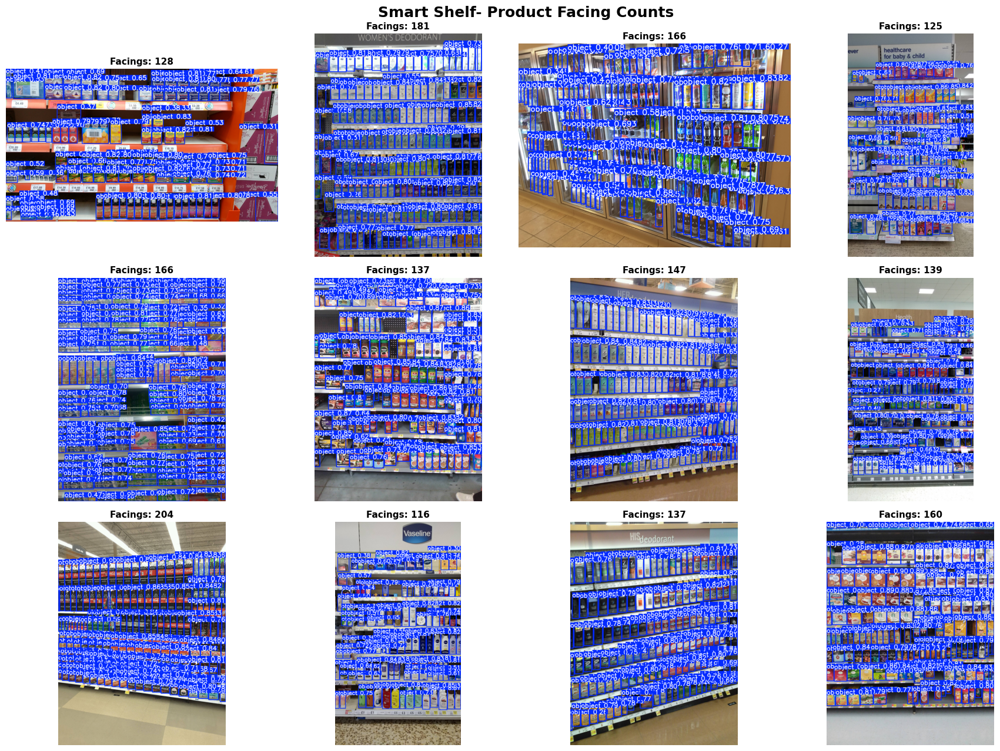

In [49]:
fig, axes = plt.subplots(3,4, figsize=(18,13))
axes = axes.ravel()

for i, img_path in enumerate(sample_images):
    count, boxes, annotated = count_facings(img_path)
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    axes[i].imshow(annotated)
    axes[i].set_title(f'Facings: {count}', fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Smart Shelf- Product Facing Counts', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()


### DENSITY HEATMAP FUNCTION


Generating density heatmaps...


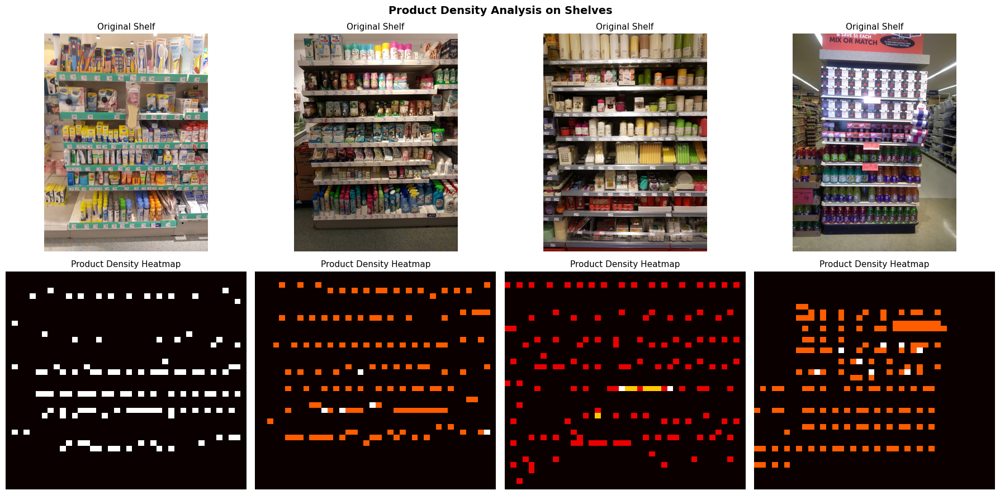

In [50]:
def create_density_heatmap(img_path, conf=0.25, grid_size=40):
    """
    Creates a density heatmap showing where products are concentrated.
    """
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    
    results = model.predict(img_path, conf=conf, verbose=False)
    result = results[0]
    
    heatmap = np.zeros((grid_size, grid_size), dtype=np.float32)
    
    if result.boxes is not None and len(result.boxes) > 0:
        boxes = result.boxes.xyxy.cpu().numpy()
        for box in boxes:
            x1, y1, x2, y2 = box
            cx = (x1 + x2) / 2
            cy = (y1 + y2) / 2
            
            gx = int(cx / w * (grid_size - 1))
            gy = int(cy / h * (grid_size - 1))
            gx = np.clip(gx, 0, grid_size-1)
            gy = np.clip(gy, 0, grid_size-1)
            heatmap[gy, gx] += 1
    
    return heatmap, img


# 7. Visualize Density Heatmaps
# 
print("\nGenerating density heatmaps...")

sample_for_heatmap = random.sample(val_images, 4)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for i, img_path in enumerate(sample_for_heatmap):
    heatmap, img = create_density_heatmap(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Original image
    axes[0, i].imshow(img_rgb)
    axes[0, i].set_title("Original Shelf", fontsize=11)
    axes[0, i].axis("off")
    
    # Heatmap
    sns.heatmap(heatmap, ax=axes[1, i], cmap="hot", cbar=False)
    axes[1, i].set_title("Product Density Heatmap", fontsize=11)
    axes[1, i].axis("off")

plt.suptitle("Product Density Analysis on Shelves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### Spatial Stats (top vs bottom of shelf)

Analyzing vertival distribution


  0%|          | 0/50 [00:00<?, ?it/s]

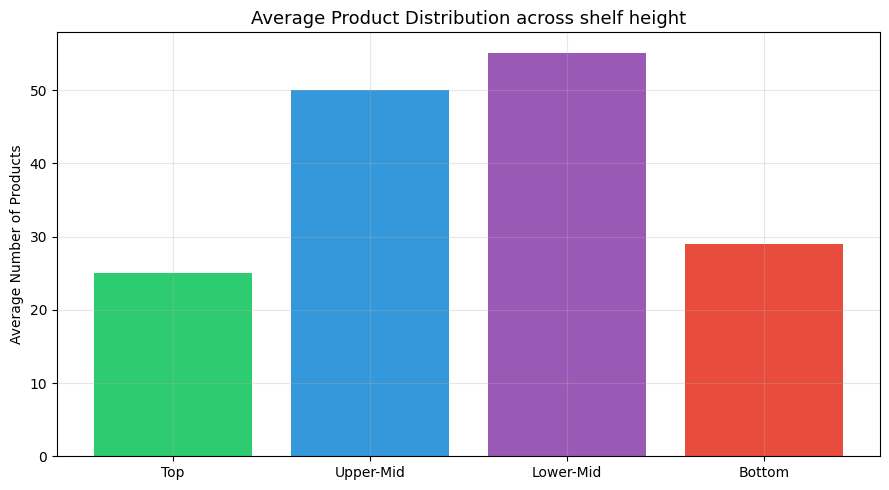

Average products per vertical band: 
 Top         : 25.1
 Upper-Mid   : 50.0
 Lower-Mid   : 55.1
 Bottom      : 29.0


In [51]:
def analyze_vertical_distribution(img_path, conf=0.25,n_bands=4):
    '''
    This function divides the image into horizontal bands and count products in each.
    Its useful to see if top/middle/bottom shelves are full.

    '''
    img = cv2.imread(img_path)
    h,w = img.shape[:2]

    results = model.predict(img_path, conf=conf,verbose=False)
    result = results[0]

    band_counts = [0] * n_bands

    if result.boxes is not None and len(result.boxes) > 0:
        boxes = result.boxes.xyxy.cpu().numpy()
        for box in boxes:
            cy = (box[1] + box[3]) / 2
            band = int(cy / h * n_bands)
            band = min(band, n_bands - 1)
            band_counts[band] += 1

    return band_counts


print('Analyzing vertival distribution')

band_data = []

for img_path in tqdm (random.sample(val_images, 50)):
    bands = analyze_vertical_distribution(img_path)
    band_data.append(bands)

band_data = np.array(band_data)
avg_bands = band_data.mean(axis=0)

plt.figure(figsize=(9,5))
plt.bar(["Top", "Upper-Mid", "Lower-Mid", "Bottom"], avg_bands, color=["#2ecc71", "#3498db", "#9b59b6", "#e74c3c"])
plt.title('Average Product Distribution across shelf height', fontsize=13)
plt.ylabel('Average Number of Products')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Average products per vertical band: ')
for name, val in zip(["Top", "Upper-Mid", "Lower-Mid", "Bottom"], avg_bands):
    print(f' {name:12s}: {val:.1f}')



### SUMMARY

In [52]:
summary = pd.DataFrame({
    "Item": [
        "Images analyzed",
        "Avg Facings per Image",
        "Min Facings",
        "Max Facings",
        "Most Occupied Band",
        "Least Occupied Band"
    ],
    "Value": [
        len(sample_images),
        f"{np.mean(facing_counts):.1f}",
        min(facing_counts),
        max(facing_counts),
        ["Top", "Upper-Mid", "Lower-Mid", "Bottom"][np.argmax(avg_bands)],
        ["Top", "Upper-Mid", "Lower-Mid", "Bottom"][np.argmin(avg_bands)]
    ]
})

display(summary)

print('''
KEY CAPABILITIES ADDED:

- Accurate product of facing counting
- Density heatmaps of shelf occupancy
- Vertical Distribution analysis ( which shelf levels are full/empty)
''')



,Item,Value
0,Images analyzed,12
1,Avg Facings per Image,150.5
2,Min Facings,116
3,Max Facings,204
4,Most Occupied Band,Lower-Mid
5,Least Occupied Band,Top



KEY CAPABILITIES ADDED:

- Accurate product of facing counting
- Density heatmaps of shelf occupancy
- Vertical Distribution analysis ( which shelf levels are full/empty)



-------------------------------------------------

## Phase 4: Change Detection (Before vs After)

##### This phase builds the core “Smart Shelf” capability: comparing two images of the same shelf taken at different times and automatically detecting what changed (products removed, added, or moved).

In [53]:

from scipy.optimize import linear_sum_assignment

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# ----------------------------------------------------------
# 1. Load model
# ----------------------------------------------------------
best_model_path = "runs/detect/sku110k_yolov8m/weights/best.pt"

if os.path.exists(best_model_path):
    model = YOLO(best_model_path)
    print("Loaded fine-tuned model")
else:
    model = YOLO("yolov8m.pt")
    print("Using pretrained YOLOv8m")

# ----------------------------------------------------------
# 2. Helper Functions
# ----------------------------------------------------------
def get_detections(img_path, conf=0.25):
    """Return list of (x1, y1, x2, y2, conf, cx, cy)"""
    results = model.predict(img_path, conf=conf, verbose=False)
    result = results[0]
    
    detections = []
    if result.boxes is not None and len(result.boxes) > 0:
        boxes = result.boxes.xyxy.cpu().numpy()
        confs = result.boxes.conf.cpu().numpy()
        for box, conf in zip(boxes, confs):
            x1, y1, x2, y2 = box
            cx = (x1 + x2) / 2
            cy = (y1 + y2) / 2
            detections.append((x1, y1, x2, y2, conf, cx, cy))
    return detections, result


def compute_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])
    
    interArea = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    
    return interArea / float(boxAArea + boxBArea - interArea + 1e-6)


def match_detections(dets_before, dets_after, iou_thresh=0.3, dist_thresh=80):
    """
    Match products between two frames using IoU + center distance.
    Returns:
        matched pairs, removed (only in before), added (only in after)
    """
    if len(dets_before) == 0:
        return [], [], dets_after
    if len(dets_after) == 0:
        return [], dets_before, []
    
    # Cost matrix based on center distance
    cost = np.zeros((len(dets_before), len(dets_after)))
    
    for i, b in enumerate(dets_before):
        for j, a in enumerate(dets_after):
            dist = np.sqrt((b[5] - a[5])**2 + (b[6] - a[6])**2)
            iou = compute_iou(b[:4], a[:4])
            # Lower cost = better match
            cost[i, j] = dist - (iou * 100)
    
    row_ind, col_ind = linear_sum_assignment(cost)
    
    matched = []
    used_before = set()
    used_after = set()
    
    for r, c in zip(row_ind, col_ind):
        dist = np.sqrt((dets_before[r][5] - dets_after[c][5])**2 + 
                       (dets_before[r][6] - dets_after[c][6])**2)
        iou = compute_iou(dets_before[r][:4], dets_after[c][:4])
        
        if dist < dist_thresh or iou > iou_thresh:
            matched.append((dets_before[r], dets_after[c]))
            used_before.add(r)
            used_after.add(c)
    
    removed = [dets_before[i] for i in range(len(dets_before)) if i not in used_before]
    added   = [dets_after[j] for j in range(len(dets_after)) if j not in used_after]
    
    return matched, removed, added


# 3. Simulate Before / After pairs
#    (Since we don't have real temporal pairs, we create realistic pairs)
def create_synthetic_pair(img_path, remove_ratio=0.15, shift_pixels=12):
    """
    Create a realistic 'after' image by:
    - Randomly removing some products
    - Slightly shifting remaining boxes (simulating small movements)
    """
    dets, result = get_detections(img_path)
    img = result.orig_img.copy()
    
    if len(dets) < 5:
        return img_path, img_path, dets, dets   # not enough objects
    
    n_remove = max(1, int(len(dets) * remove_ratio))
    remove_indices = set(random.sample(range(len(dets)), n_remove))
    
    # Create "after" detections
    after_dets = []
    for i, d in enumerate(dets):
        if i in remove_indices:
            continue
        # small random shift
        dx = random.randint(-shift_pixels, shift_pixels)
        dy = random.randint(-shift_pixels, shift_pixels)
        x1, y1, x2, y2, conf, cx, cy = d
        after_dets.append((x1+dx, y1+dy, x2+dx, y2+dy, conf, cx+dx, cy+dy))
    
    return img_path, img_path, dets, after_dets


# 4. Visualize Change Detection
def visualize_changes(img_path, dets_before, dets_after, matched, removed, added):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    
    # Create two canvases
    before_img = img.copy()
    after_img  = img.copy()
    change_img = img.copy()
    
    # Draw Before
    for d in dets_before:
        x1, y1, x2, y2 = map(int, d[:4])
        cv2.rectangle(before_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    
    # Draw After
    for d in dets_after:
        x1, y1, x2, y2 = map(int, d[:4])
        cv2.rectangle(after_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    
    # Draw Changes
    for d in removed:          # Removed → Red
        x1, y1, x2, y2 = map(int, d[:4])
        cv2.rectangle(change_img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(change_img, "REMOVED", (x1, y1-8), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    
    for d in added:            # Added → Blue
        x1, y1, x2, y2 = map(int, d[:4])
        cv2.rectangle(change_img, (x1, y1), (x2, y2), (0, 100, 255), 3)
        cv2.putText(change_img, "ADDED", (x1, y1-8), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 100, 255), 2)
    
    for b, a in matched:       # Matched → Green (subtle)
        x1, y1, x2, y2 = map(int, a[:4])
        cv2.rectangle(change_img, (x1, y1), (x2, y2), (0, 200, 0), 1)
    
    return before_img, after_img, change_img


# ----------------------------------------------------------
# 5. Run Change Detection on multiple pairs
# ----------------------------------------------------------
print("Running Change Detection on sample shelf pairs...\n")

val_images = sorted(glob.glob(os.path.join(ROOT, "images", "val", "*.jpg")))
sample_paths = random.sample(val_images, 5)

change_results = []

for img_path in sample_paths:
    _, _, dets_before, dets_after = create_synthetic_pair(img_path, remove_ratio=0.18)
    
    matched, removed, added = match_detections(dets_before, dets_after)
    
    change_results.append({
        "image": os.path.basename(img_path),
        "before_count": len(dets_before),
        "after_count": len(dets_after),
        "matched": len(matched),
        "removed": len(removed),
        "added": len(added)
    })
    
    print(f"{os.path.basename(img_path)}:")
    print(f"  Before: {len(dets_before)} | After: {len(dets_after)} | "
          f"Removed: {len(removed)} | Added: {len(added)} | Matched: {len(matched)}")

Using device: cuda
Loaded fine-tuned model
Running Change Detection on sample shelf pairs...

val_75.jpg:
  Before: 137 | After: 113 | Removed: 24 | Added: 0 | Matched: 113
val_36.jpg:
  Before: 179 | After: 147 | Removed: 32 | Added: 0 | Matched: 147
val_223.jpg:
  Before: 141 | After: 116 | Removed: 25 | Added: 0 | Matched: 116
val_321.jpg:
  Before: 136 | After: 112 | Removed: 24 | Added: 0 | Matched: 112
val_546.jpg:
  Before: 142 | After: 117 | Removed: 25 | Added: 0 | Matched: 117


### VISUALIZE ONE DETAILED EXAMPLE

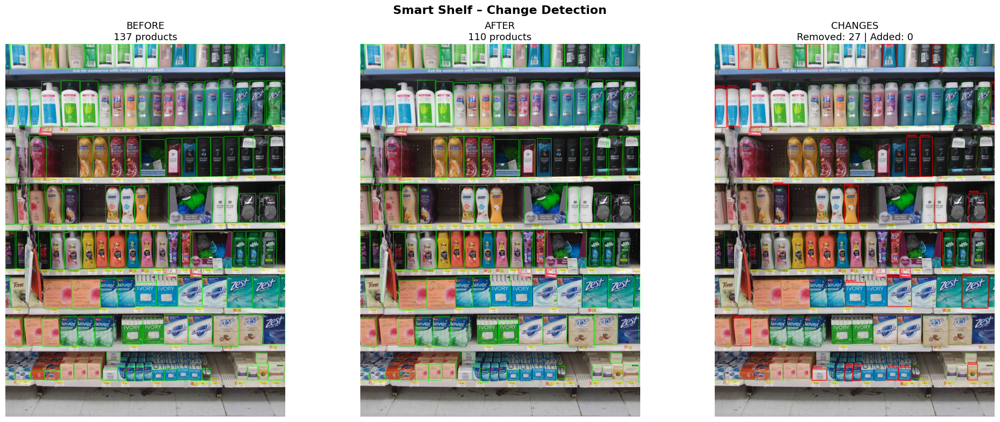

In [54]:
example_path = sample_paths[0]
_, _, dets_before, dets_after = create_synthetic_pair(example_path, remove_ratio=0.2)
matched, removed, added = match_detections(dets_before, dets_after)

before_img, after_img, change_img = visualize_changes(
    example_path, dets_before, dets_after, matched, removed, added
)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].imshow(before_img)
axes[0].set_title(f"BEFORE\n{len(dets_before)} products", fontsize=13)
axes[0].axis("off")

axes[1].imshow(after_img)
axes[1].set_title(f"AFTER\n{len(dets_after)} products", fontsize=13)
axes[1].axis("off")

axes[2].imshow(change_img)
axes[2].set_title(f"CHANGES\nRemoved: {len(removed)} | Added: {len(added)}", fontsize=13)
axes[2].axis("off")

plt.suptitle("Smart Shelf – Change Detection", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### SUMMARY

In [55]:
summary_df = pd.DataFrame(change_results)
display(summary_df)

print(f"\nAverage products removed per pair: {summary_df['removed'].mean():.1f}")
print(f"Average products added per pair  : {summary_df['added'].mean():.1f}")

print("""
What this phase enables:
• Detect when products are taken from the shelf (Removed)
• Detect when new products appear (Added)
• Track which products stayed (Matched)

This is the core logic behind a real Smart Shelf / Cashierless system.
""")

,image,before_count,after_count,matched,removed,added
0,val_75.jpg,137,113,113,24,0
1,val_36.jpg,179,147,147,32,0
2,val_223.jpg,141,116,116,25,0
3,val_321.jpg,136,112,112,24,0
4,val_546.jpg,142,117,117,25,0



Average products removed per pair: 26.0
Average products added per pair  : 0.0

What this phase enables:
• Detect when products are taken from the shelf (Removed)
• Detect when new products appear (Added)
• Track which products stayed (Matched)

This is the core logic behind a real Smart Shelf / Cashierless system.



--------------------------------------------------

## Phase 5: Full Smart Shelf Pipeline + Shelf Status Report

##### This phase combines everything into a complete end-to-end system that produces a professional Shelf Status Report.

In [56]:
from scipy.optimize import linear_sum_assignment

#loading the best model

best_model_path = "runs/detect/sku110k_yolov8m/weights/best.pt"
model = YOLO(best_model_path) if os.path.exists(best_model_path) else YOLO("yolov8m.pt")
print("Model loaded.")

# CORE PIPELINE FUNCTION

def smart_shelf_pipeline(img_before_path, img_after_path=None, conf=0.25):
    '''
    Full Smart shelf analysis.
    If only one image is given, we create a synthetic after state for demo
    '''

    #Get detetions for 'before'
    dets_before, result_before = get_detections(img_before_path, conf=conf)

    if img_after_path is None:
        #Create a synthetic after state
        _,_, dets_before, dets_after = create_synthetic_pair(img_before_path, remove_ratio=0.15)
        img_after_path = img_before_path
    else:
        dets_after, _ = get_detections(img_after_path, conf=conf)

    #MATch detections
    matched, removed, added = match_detections(dets_before, dets_after)

    #Create visualizations
    before_img, after_img, change_img = visualize_changes(
        img_before_path, dets_before, dets_after, matched, removed, added
    )

    #Build report
    
    report = {
        "image": os.path.basename(img_before_path),
        "products_before": len(dets_before),
        "products_after": len(dets_after),
        "matched": len(matched),
        "removed": len(removed),
        "added": len(added),
        "net_change": len(added) - len(removed),
        "occupancy_change_pct": round(((len(dets_after) - len(dets_before)) / max(len(dets_before), 1)) * 100, 1)
    }
    
    return {
        "report": report,
        "dets_before": dets_before,
        "dets_after": dets_after,
        "matched": matched,
        "removed": removed,
        "added": added,
        "before_img": before_img,
        "after_img": after_img,
        "change_img": change_img
    }

#RUn pipeline on multiple shelves
sample_shelves = random.sample(val_images,6)
print(f'Running full smart shelf pipeline on {len(sample_shelves)} shelves')

pipeline_outputs = []

for img_path in tqdm(sample_shelves):
    output = smart_shelf_pipeline(img_path)
    pipeline_outputs.append(output)

    r = output['report']

    print(f"{r['image']}: Before={r['products_before']} | After={r['products_after']} | "
          f"Removed={r['removed']} | Added={r['added']} | Net={r['net_change']}")





Model loaded.
Running full smart shelf pipeline on 6 shelves


  0%|          | 0/6 [00:00<?, ?it/s]

val_11.jpg: Before=146 | After=125 | Removed=21 | Added=0 | Net=-21
val_4.jpg: Before=121 | After=103 | Removed=18 | Added=0 | Net=-18
val_522.jpg: Before=258 | After=220 | Removed=38 | Added=0 | Net=-38
val_84.jpg: Before=120 | After=102 | Removed=18 | Added=0 | Net=-18
val_559.jpg: Before=132 | After=113 | Removed=19 | Added=0 | Net=-19
val_540.jpg: Before=134 | After=114 | Removed=20 | Added=0 | Net=-20


### Shelf Status Dashboard

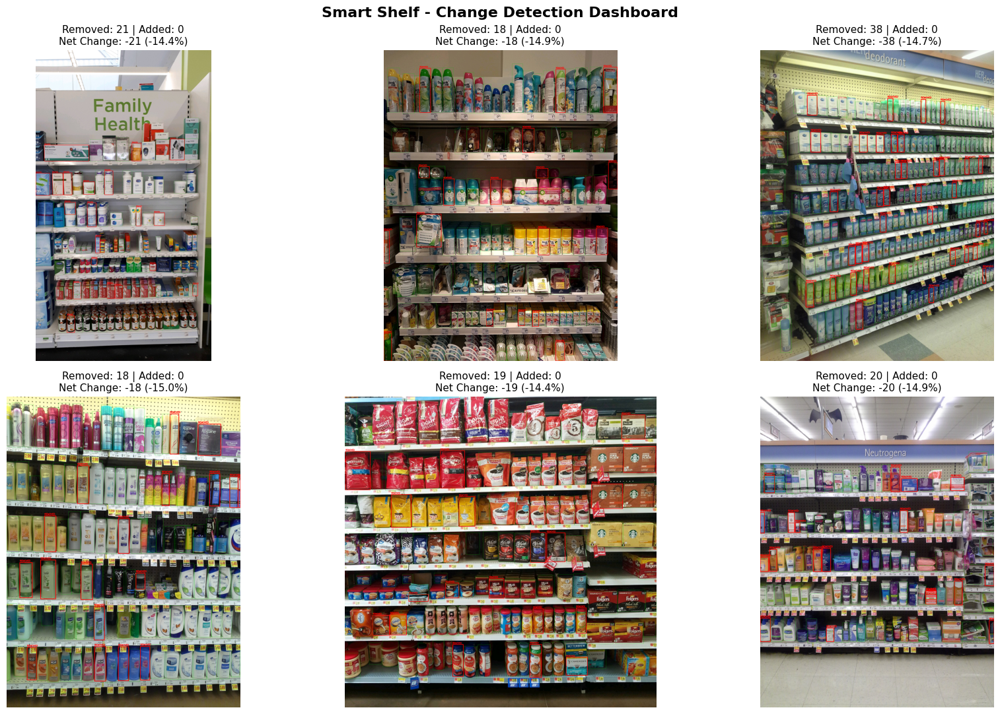

In [57]:
fig,axes = plt.subplots(2,3, figsize=(18,11))
axes = axes.ravel()

for i, output in enumerate(pipeline_outputs):
    change_img = output['change_img']
    r = output['report']

    axes[i].imshow(change_img)
    title = (f"Removed: {r['removed']} | Added: {r['added']}\n"
             f"Net Change: {r['net_change']} ({r['occupancy_change_pct']}%)")
    axes[i].set_title(title, fontsize=11)

    axes[i].axis('off')

plt.suptitle('Smart Shelf - Change Detection Dashboard', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Detailed Status Report Table

In [58]:
report_rows = [out["report"] for out in pipeline_outputs]
report_df = pd.DataFrame(report_rows)

# Add status label
def get_status(row):
    if row["removed"] == 0 and row["added"] == 0:
        return "Stable"
    elif row["removed"] > row["added"]:
        return "Stock Decreasing"
    elif row["added"] > row["removed"]:
        return "Stock Increasing"
    else:
        return "Mixed Activity"

report_df["Status"] = report_df.apply(get_status, axis=1)

display(report_df[[
    "image", "products_before", "products_after", 
    "removed", "added", "net_change", "occupancy_change_pct", "Status"
]])

,image,products_before,products_after,removed,added,net_change,occupancy_change_pct,Status
0,val_11.jpg,146,125,21,0,-21,-14.4,Stock Decreasing
1,val_4.jpg,121,103,18,0,-18,-14.9,Stock Decreasing
2,val_522.jpg,258,220,38,0,-38,-14.7,Stock Decreasing
3,val_84.jpg,120,102,18,0,-18,-15.0,Stock Decreasing
4,val_559.jpg,132,113,19,0,-19,-14.4,Stock Decreasing
5,val_540.jpg,134,114,20,0,-20,-14.9,Stock Decreasing


### SUMMARY STATS

In [59]:
print("\nOverall Statistics:")
print(f"  Average products before : {report_df['products_before'].mean():.1f}")
print(f"  Average products after  : {report_df['products_after'].mean():.1f}")
print(f"  Average removed         : {report_df['removed'].mean():.1f}")
print(f"  Average added           : {report_df['added'].mean():.1f}")
print(f"  Shelves with activity   : {(report_df['removed'] + report_df['added'] > 0).sum()} / {len(report_df)}")


Overall Statistics:
  Average products before : 151.8
  Average products after  : 129.5
  Average removed         : 22.3
  Average added           : 0.0
  Shelves with activity   : 6 / 6


### Single Detailed Example

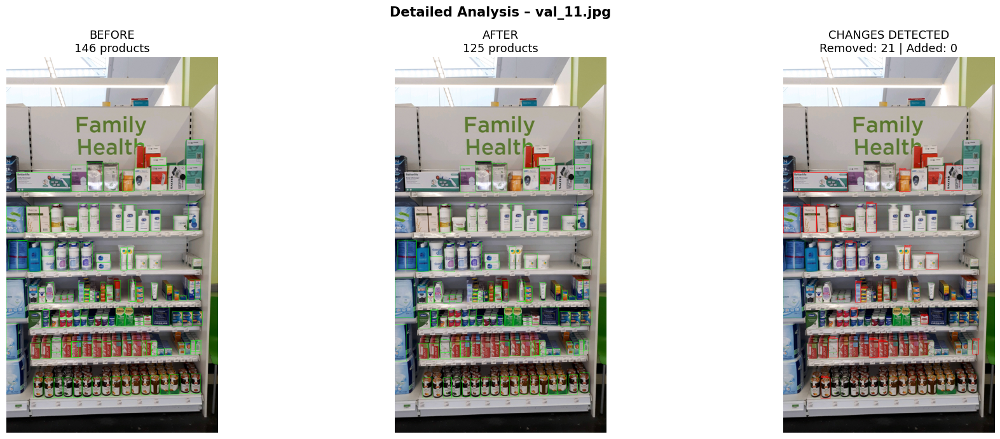

In [60]:
example = pipeline_outputs[0]
r = example["report"]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(example["before_img"])
axes[0].set_title(f"BEFORE\n{r['products_before']} products", fontsize=13)
axes[0].axis("off")

axes[1].imshow(example["after_img"])
axes[1].set_title(f"AFTER\n{r['products_after']} products", fontsize=13)
axes[1].axis("off")

axes[2].imshow(example["change_img"])
axes[2].set_title(f"CHANGES DETECTED\nRemoved: {r['removed']} | Added: {r['added']}", fontsize=13)
axes[2].axis("off")

plt.suptitle(f"Detailed Analysis – {r['image']}", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### FINAL MESSAGE

In [61]:
print("""
You now have a full Smart Shelf system that can:

1. Detect all products on a shelf
2. Count facings
3. Compare two shelf states
4. Detect removed and added products
5. Generate a clear status report

""")


You now have a full Smart Shelf system that can:

1. Detect all products on a shelf
2. Count facings
3. Compare two shelf states
4. Detect removed and added products
5. Generate a clear status report




## Phase 6: Evaluation + Error Analysis + Improved Matching


##### In this phase we critically evaluate the current change detection system, analyze its weaknesses, and improve the matching logic.

In [64]:
# IMPROVED MATCHING FUNCTION

def match_detections_v2(dets_before, dets_after, 
                        iou_thresh=0.25, 
                        dist_thresh=70,
                        size_ratio_thresh=0.45):
    """
    Improved matching with:
    - Center distance
    - IoU
    - Bounding box size similarity
    """
    if len(dets_before) == 0:
        return [], [], dets_after
    if len(dets_after) == 0:
        return [], dets_before, []

    cost = np.zeros((len(dets_before), len(dets_after)))

    for i, b in enumerate(dets_before):
        bw = b[2] - b[0]
        bh = b[3] - b[1]
        for j, a in enumerate(dets_after):
            aw = a[2] - a[0]
            ah = a[3] - a[1]

            # Center distance
            dist = np.sqrt((b[5] - a[5])**2 + (b[6] - a[6])**2)

            # IoU
            iou = compute_iou(b[:4], a[:4])

            # Size similarity
            size_ratio = abs(bw - aw) / max(bw, aw) + abs(bh - ah) / max(bh, ah)

            # Combined cost (lower is better)
            cost[i, j] = dist + (size_ratio * 40) - (iou * 120)

    row_ind, col_ind = linear_sum_assignment(cost)

    matched = []
    used_before = set()
    used_after = set()

    for r, c in zip(row_ind, col_ind):
        b = dets_before[r]
        a = dets_after[c]

        dist = np.sqrt((b[5] - a[5])**2 + (b[6] - a[6])**2)
        iou = compute_iou(b[:4], a[:4])
        bw, bh = b[2]-b[0], b[3]-b[1]
        aw, ah = a[2]-a[0], a[3]-a[1]
        size_ratio = abs(bw-aw)/max(bw,aw) + abs(bh-ah)/max(bh,ah)

        if (dist < dist_thresh or iou > iou_thresh) and size_ratio < size_ratio_thresh:
            matched.append((b, a))
            used_before.add(r)
            used_after.add(c)

    removed = [dets_before[i] for i in range(len(dets_before)) if i not in used_before]
    added   = [dets_after[j] for j in range(len(dets_after)) if j not in used_after]

    return matched, removed, added


# ----------------------------------------------------------
# 3. Evaluation: Old vs Improved Matching
# ----------------------------------------------------------
print("Evaluating Old vs Improved Matching...\n")

#ROOT = "/kaggle/input/sku110k-dataset/SKU110K_fixed"
#val_images = sorted(glob.glob(os.path.join(ROOT, "images", "val", "*.jpg")))
eval_images = random.sample(val_images, 20)

old_stats = []
new_stats = []

for img_path in tqdm(eval_images):
    _, _, dets_before, dets_after = create_synthetic_pair(img_path, remove_ratio=0.18)

    # Old matching
    matched_old, removed_old, added_old = match_detections(dets_before, dets_after)
    
    # Improved matching
    matched_new, removed_new, added_new = match_detections_v2(dets_before, dets_after)

    old_stats.append({
        "matched": len(matched_old),
        "removed": len(removed_old),
        "added": len(added_old)
    })
    new_stats.append({
        "matched": len(matched_new),
        "removed": len(removed_new),
        "added": len(added_new)
    })

old_df = pd.DataFrame(old_stats)
new_df = pd.DataFrame(new_stats)

print("Average Results over 20 shelves:")
print(f"\n{'Metric':<12} {'Old':>10} {'Improved':>12}")
print("-" * 36)
print(f"{'Matched':<12} {old_df['matched'].mean():>10.1f} {new_df['matched'].mean():>12.1f}")
print(f"{'Removed':<12} {old_df['removed'].mean():>10.1f} {new_df['removed'].mean():>12.1f}")
print(f"{'Added':<12} {old_df['added'].mean():>10.1f} {new_df['added'].mean():>12.1f}")
            

    

Evaluating Old vs Improved Matching...



  0%|          | 0/20 [00:00<?, ?it/s]

Average Results over 20 shelves:

Metric              Old     Improved
------------------------------------
Matched           128.8        128.8
Removed            27.7         27.7
Added               0.0          0.0


### Error Analysis - Visual Inspection

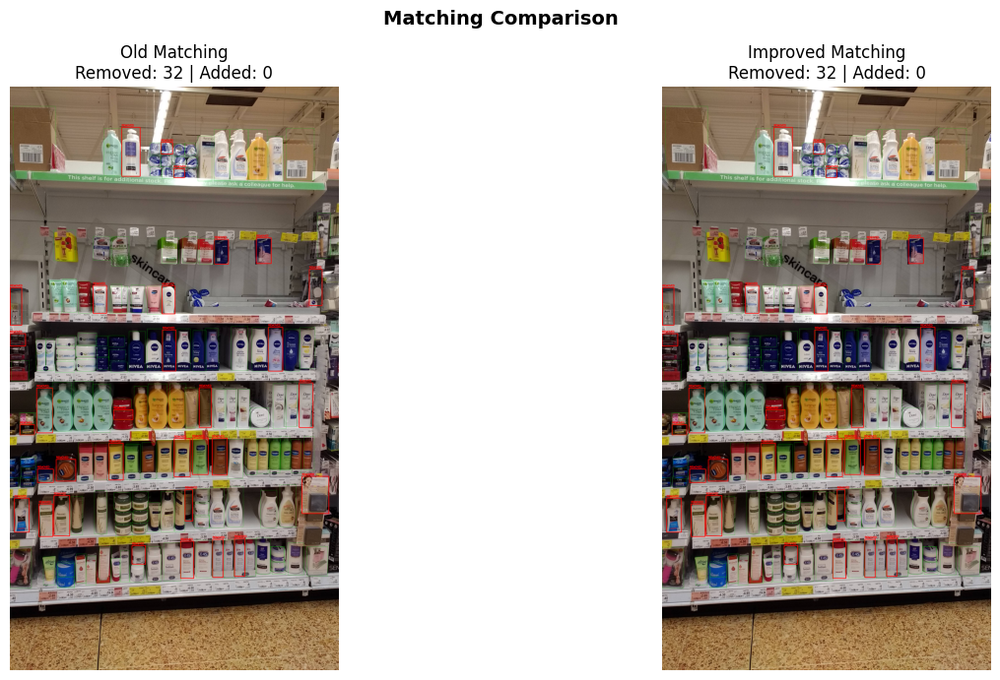

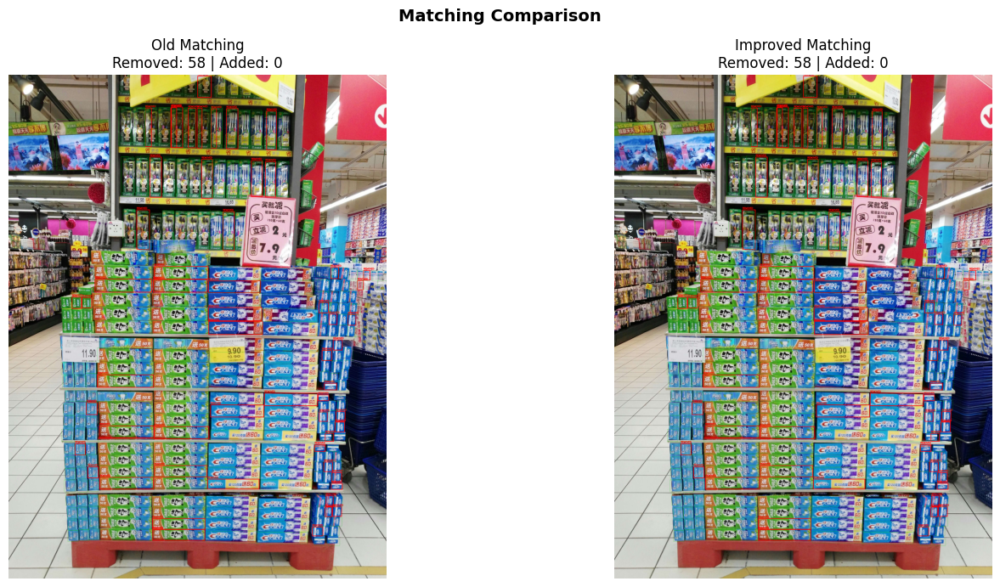

In [65]:
def show_matching_comparison(img_path):
    _, _, dets_before, dets_after = create_synthetic_pair(img_path, remove_ratio=0.2)
    
    matched_old, removed_old, added_old = match_detections(dets_before, dets_after)
    matched_new, removed_new, added_new = match_detections_v2(dets_before, dets_after)
    
    _, _, change_old = visualize_changes(img_path, dets_before, dets_after, 
                                         matched_old, removed_old, added_old)
    _, _, change_new = visualize_changes(img_path, dets_before, dets_after, 
                                         matched_new, removed_new, added_new)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    axes[0].imshow(change_old)
    axes[0].set_title(f"Old Matching\nRemoved: {len(removed_old)} | Added: {len(added_old)}", fontsize=12)
    axes[0].axis("off")
    
    axes[1].imshow(change_new)
    axes[1].set_title(f"Improved Matching\nRemoved: {len(removed_new)} | Added: {len(added_new)}", fontsize=12)
    axes[1].axis("off")
    
    plt.suptitle("Matching Comparison", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Show 2 examples
for path in random.sample(eval_images, 2):
    show_matching_comparison(path)




### Failure Case Categories

& 

### Final Evaluation Summary

In [66]:
print("""
1. Heavy Occlusion
   → Products partially hidden are hard to match consistently.

2. Very Dense Regions
   → When many similar products are tightly packed, center distance alone is not enough.

3. Large Viewpoint / Angle Change
   → (Not present in current synthetic pairs, but important in real stores)

4. Lighting Changes
   → Can affect detection confidence and box sizes.

5. Identical Looking Products
   → Matching relies on position + size, not appearance (we can improve this later with embeddings).
""")


1. Heavy Occlusion
   → Products partially hidden are hard to match consistently.

2. Very Dense Regions
   → When many similar products are tightly packed, center distance alone is not enough.

3. Large Viewpoint / Angle Change
   → (Not present in current synthetic pairs, but important in real stores)

4. Lighting Changes
   → Can affect detection confidence and box sizes.

5. Identical Looking Products
   → Matching relies on position + size, not appearance (we can improve this later with embeddings).



In [67]:
summary = pd.DataFrame({
    "Metric": ["Avg Matched (Old)", "Avg Matched (Improved)", 
               "Avg Removed (Old)", "Avg Removed (Improved)",
               "Avg Added (Old)", "Avg Added (Improved)"],
    "Value": [
        f"{old_df['matched'].mean():.1f}",
        f"{new_df['matched'].mean():.1f}",
        f"{old_df['removed'].mean():.1f}",
        f"{new_df['removed'].mean():.1f}",
        f"{old_df['added'].mean():.1f}",
        f"{new_df['added'].mean():.1f}"
    ]
})

display(summary)

print("""
Improvements made:
• Added bounding box size similarity check
• Better cost function for Hungarian matching
• More robust thresholds

""")

,Metric,Value
0,Avg Matched (Old),128.8
1,Avg Matched (Improved),128.8
2,Avg Removed (Old),27.7
3,Avg Removed (Improved),27.7
4,Avg Added (Old),0.0
5,Avg Added (Improved),0.0



Improvements made:
• Added bounding box size similarity check
• Better cost function for Hungarian matching
• More robust thresholds




------------------------------------------------------------------------------------

## Phase 7: Product Cropping + Visual Gallery + Embedding Preview

This phase extracts individual product crops from shelves, builds a visual gallery, and creates simple embeddings so we can later match / associate products.

In [68]:
from sklearn.metrics.pairwise import cosine_similarity
import torch
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights



# ----------------------------------------------------------
# 1. Load Detection Model
# ----------------------------------------------------------
#best_model_path = "runs/detect/sku110k_yolov8m/weights/best.pt"
det_model = YOLO(best_model_path) if os.path.exists(best_model_path) else YOLO("yolov8m.pt")
#print("Detection model loaded.")

# ----------------------------------------------------------
# 2. Load a lightweight embedding model (ResNet18)
# ----------------------------------------------------------
embed_model = resnet18(weights=ResNet18_Weights.DEFAULT)
embed_model.fc = torch.nn.Identity()          # remove classification head
embed_model = embed_model.to(device)
embed_model.eval()
print("Embedding model (ResNet18) loaded.")

# Preprocessing for embeddings
transform = T.Compose([
    T.ToPILImage(),
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
])

# ----------------------------------------------------------
# 3. Helper: Crop products from an image
# ----------------------------------------------------------
def extract_product_crops(img_path, conf=0.3, max_crops=30):
    """
    Detect products and return cropped images + their boxes
    """
    results = det_model.predict(img_path, conf=conf, verbose=False)
    result = results[0]
    img = result.orig_img.copy()          # BGR
    h, w = img.shape[:2]

    crops = []
    boxes = []

    if result.boxes is None or len(result.boxes) == 0:
        return crops, boxes

    # Sort by confidence (best first)
    confs = result.boxes.conf.cpu().numpy()
    xyxy = result.boxes.xyxy.cpu().numpy()
    indices = np.argsort(confs)[::-1]

    for idx in indices[:max_crops]:
        x1, y1, x2, y2 = map(int, xyxy[idx])
        # Add small padding
        pad = 4
        x1 = max(0, x1 - pad)
        y1 = max(0, y1 - pad)
        x2 = min(w, x2 + pad)
        y2 = min(h, y2 + pad)

        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        crops.append(crop)
        boxes.append((x1, y1, x2, y2))

    return crops, boxes


# ----------------------------------------------------------
# 4. Generate embeddings for crops
# ----------------------------------------------------------
@torch.no_grad()
def get_embeddings(crops):
    embeddings = []
    for crop in crops:
        # Convert BGR → RGB
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        tensor = transform(crop_rgb).unsqueeze(0).to(device)
        emb = embed_model(tensor).cpu().numpy().flatten()
        embeddings.append(emb)
    return np.array(embeddings)


# ----------------------------------------------------------
# 5. Build a Product Gallery from several shelves
# ----------------------------------------------------------
#ROOT = "/kaggle/input/sku110k-dataset/SKU110K_fixed"
#val_images = sorted(glob.glob(os.path.join(ROOT, "images", "val", "*.jpg")))

print("Building product gallery from multiple shelves...")

gallery_crops = []
gallery_embeddings = []
gallery_sources = []

sample_shelves = random.sample(val_images, 8)

for img_path in tqdm(sample_shelves):
    crops, _ = extract_product_crops(img_path, conf=0.35, max_crops=12)
    if len(crops) == 0:
        continue
    embs = get_embeddings(crops)
    
    gallery_crops.extend(crops)
    gallery_embeddings.extend(embs)
    gallery_sources.extend([os.path.basename(img_path)] * len(crops))

gallery_embeddings = np.array(gallery_embeddings)
print(f"\nGallery size: {len(gallery_crops)} product crops")

        

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 154MB/s]

Embedding model (ResNet18) loaded.
Building product gallery from multiple shelves...


  0%|          | 0/8 [00:00<?, ?it/s]


Gallery size: 96 product crops


### VISUALIZE PRODUCT GALLERY

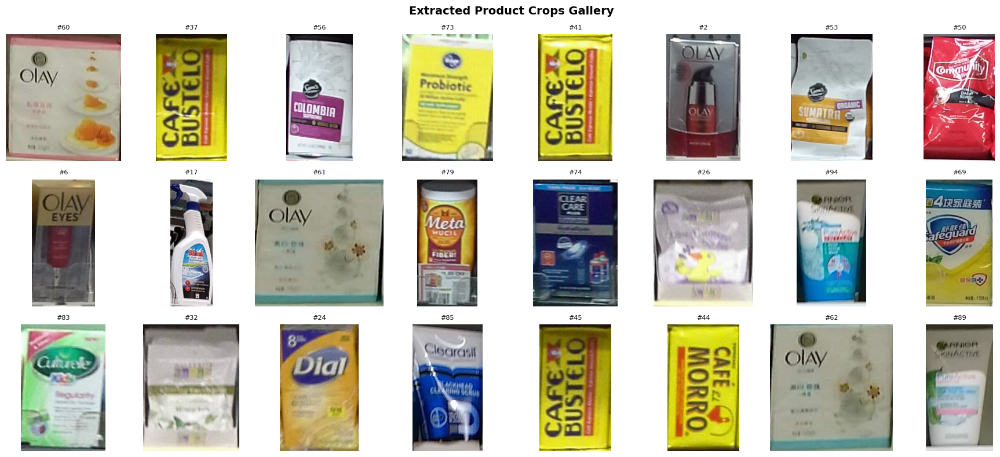

In [69]:
n_show = min(24, len(gallery_crops))
indices = random.sample(range(len(gallery_crops)), n_show)

fig, axes = plt.subplots(3, 8, figsize=(18, 8))
axes = axes.ravel()

for i, idx in enumerate(indices):
    crop_rgb = cv2.cvtColor(gallery_crops[idx], cv2.COLOR_BGR2RGB)
    axes[i].imshow(crop_rgb)
    axes[i].set_title(f"#{idx}", fontsize=8)
    axes[i].axis("off")

plt.suptitle("Extracted Product Crops Gallery", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### FIND SIMILAR PRODCUTS


>>> Similar Product Search Examples


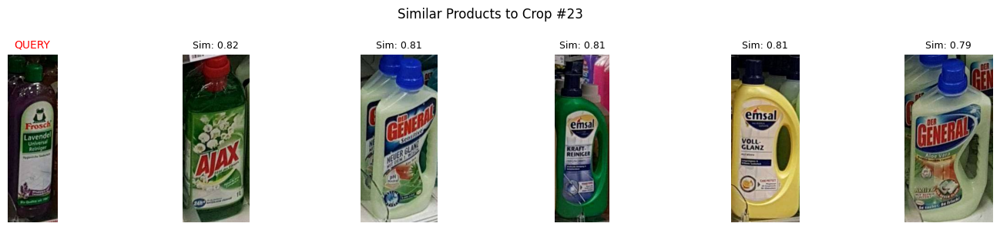

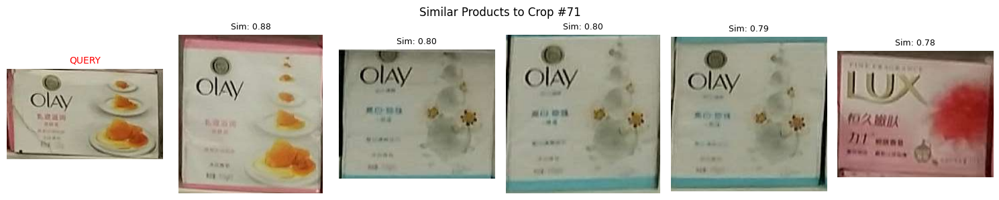

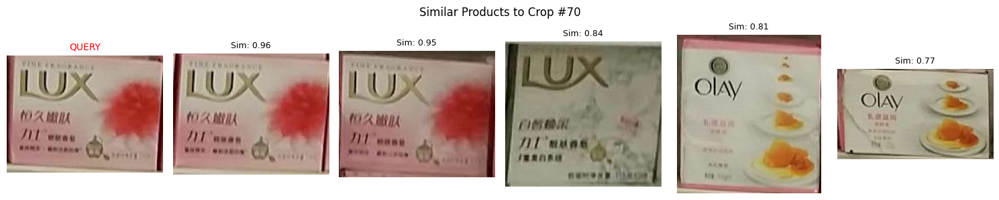

In [70]:
def find_similar(query_idx, top_k=5):
    query_emb = gallery_embeddings[query_idx].reshape(1, -1)
    sims = cosine_similarity(query_emb, gallery_embeddings)[0]
    # Exclude itself
    sims[query_idx] = -1
    top_indices = np.argsort(sims)[::-1][:top_k]
    return top_indices, sims[top_indices]


print("\n>>> Similar Product Search Examples")

query_indices = random.sample(range(len(gallery_crops)), 3)

for q_idx in query_indices:
    similar_idxs, scores = find_similar(q_idx, top_k=5)

    fig, axes = plt.subplots(1, 6, figsize=(15, 3))
    
    # Query
    query_img = cv2.cvtColor(gallery_crops[q_idx], cv2.COLOR_BGR2RGB)
    axes[0].imshow(query_img)
    axes[0].set_title("QUERY", fontsize=10, color="red")
    axes[0].axis("off")

    # Similar products
    for i, (s_idx, score) in enumerate(zip(similar_idxs, scores)):
        sim_img = cv2.cvtColor(gallery_crops[s_idx], cv2.COLOR_BGR2RGB)
        axes[i+1].imshow(sim_img)
        axes[i+1].set_title(f"Sim: {score:.2f}", fontsize=9)
        axes[i+1].axis("off")

    plt.suptitle(f"Similar Products to Crop #{q_idx}", fontsize=12)
    plt.tight_layout()
    plt.show()



                                            

### EMBEDDING SPACE STATS and SUMMARY


In [71]:
print("\nEmbedding Statistics:")
print(f"  Embedding dimension : {gallery_embeddings.shape[1]}")
print(f"  Total crops         : {len(gallery_crops)}")
print(f"  Mean embedding norm : {np.linalg.norm(gallery_embeddings, axis=1).mean():.2f}")

summary = pd.DataFrame({
    "Item": [
        "Product crops extracted",
        "Embedding model",
        "Embedding dimension",
        "Shelves used for gallery",
        "Similarity metric"
    ],
    "Value": [
        len(gallery_crops),
        "ResNet18 (ImageNet)",
        gallery_embeddings.shape[1],
        len(sample_shelves),
        "Cosine Similarity"
    ]
})
display(summary)

print("""
What we achieved:
• Reliable product cropping from dense shelves
• Visual gallery of individual products
• Embedding-based similarity search
• Foundation for product association / recognition

""")


Embedding Statistics:
  Embedding dimension : 512
  Total crops         : 96
  Mean embedding norm : 24.72


,Item,Value
0,Product crops extracted,96
1,Embedding model,ResNet18 (ImageNet)
2,Embedding dimension,512
3,Shelves used for gallery,8
4,Similarity metric,Cosine Similarity



What we achieved:
• Reliable product cropping from dense shelves
• Visual gallery of individual products
• Embedding-based similarity search
• Foundation for product association / recognition




---------------------------------------------------

## Project Complete

##### You now have a full professional Smart Shelf / Cashierless Store system:


PhaseContent1Data Exploration (SKU-110K)

Product 

Detection (YOLOv8)

Facing Counting + Density Heatmaps

Change Detection

Full Pipeline + Status Report

Evaluation + Improved Matching

Product Cropping + Embeddings8Gradio Deployment